# 1. Aim of the notebook

In this notebook we will select specific regions of interest to apply troutpy on, with the aim of characterizing the nature of transcripts outside segmented regions

## Import packages

In [2]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../../src/troutpy_reproducibility'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from roi_processing import *

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


## Read main path to .zarr file

In [3]:
inpath = "/media/sergio/Meninges/troutpy/raw/xenium_putamen/output-XETG00047__0011146__1886P__20231102__180733"
sdata = spatialdata_io.xenium(inpath)

output_path = "/media/sergio/Meninges/troutpy/rois/xenium_hsputamen"

INFO     reading                                                                                                   
         /media/sergio/Meninges/troutpy/raw/xenium_putamen/output-XETG00047__0011146__1886P__20231102__180733/cell_
         feature_matrix.h5                                                                                         


We decide to keep the data in a unified scale (um), which then can be transformated to 'global' coordinates using the according transformation. This global transformation is specially useful for matching the sales of transcripts with ie images

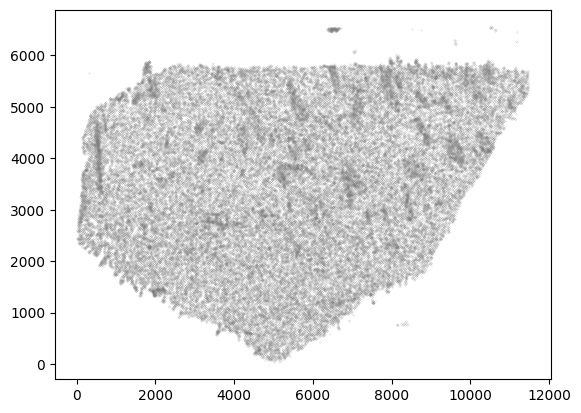

In [4]:
# Visualize using global coordinates
local_coords = sdata['table'].obsm['spatial']
# In case it's needed, chec transformations
#print(  get_transformation(sdata["nucleus_boundaries"]))
spat=[g[0] for g in sdata['table'].obsm['spatial']]
spat2=[g[1] for g in sdata['table'].obsm['spatial']]
plt.scatter(spat,spat2,s=0.01,c='grey')

In [8]:
sdata

SpatialData object
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 30914, 54014), (1, 15457, 27007), (1, 7728, 13503), (1, 3864, 6751), (1, 1932, 3375)
│     └── 'morphology_mip': DataTree[cyx] (1, 30914, 54014), (1, 15457, 27007), (1, 7728, 13503), (1, 3864, 6751), (1, 1932, 3375)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (30914, 54014), (15457, 27007), (7728, 13503), (3864, 6751), (1932, 3375)
│     └── 'nucleus_labels': DataTree[yx] (30914, 54014), (15457, 27007), (7728, 13503), (3864, 6751), (1932, 3375)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (82715, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (82715, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (82715, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (82715, 366)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_focus (Images), morphology_mi

In [17]:
# ROI selection
bb_xmin =9000# mix x 
bb_ymin= 12000 #min y
bb_xmax=40019 # max x
bb_ymax=25089.9 # max y

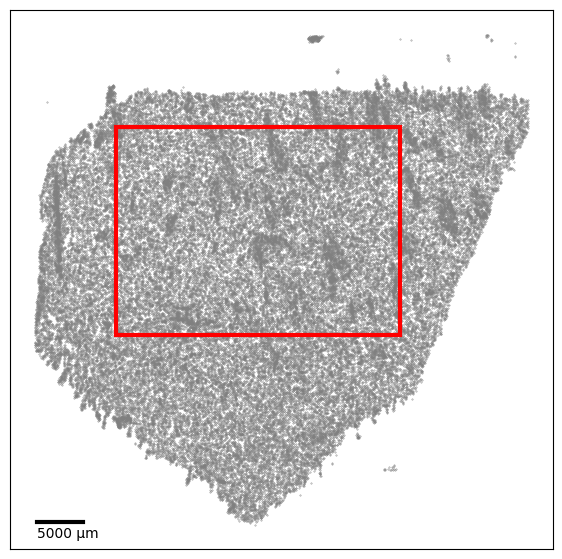

In [18]:
plot_spatial_with_box_and_scale(
    spatial_coords=sdata['table'].obsm['spatial'],
    bb_xmin=bb_xmin,
    bb_xmax=bb_xmax,
    bb_ymin=bb_ymin,
    bb_ymax=bb_ymax
)


Next, we select the ROI of interest

In [19]:
cropped_sdata = sdata.query.bounding_box(
    axes=["x", "y"],min_coordinate=[bb_xmin, bb_ymin],
    max_coordinate=[bb_xmax, bb_ymax],target_coordinate_system="global")

# Save metadata
metadata = generate_metadata(sdata=cropped_sdata,
    sample_id="human_putamen",
    species="Hommo Sapiens",technology="Xenium",
    segmentation_method="nuclei",roi_name="roi_hs_putamen",
    tissue="brain (striatum)",disease="control")

rechunk_sdata(cropped_sdata)


Processing image: morphology_mip
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing image: morphology_focus
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: nucleus_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale: scale2
  Applying chunking...
  Rechunking scale: scale3
  Applying chunking...
  Rechunking scale: scale4
  Applying chunking...
Processing label: cell_labels
  Rechunking scale: scale0
  Applying chunking...
  Rechunking scale: scale1
  Applying chunking...
  Rechunking scale:

In [20]:
sdata['transcripts'].compute()

,x,y,z,feature_name,cell_id,overlaps_nucleus,transcript_id,qv,nucleus_distance,fov_name
0,113.092682,1438.816895,11.850719,SLC17A6,UNASSIGNED,0,281565171025170,26.689711,659.502808,N1
1,224.699265,1471.866211,11.735926,NegControlProbe_00022,UNASSIGNED,0,281565171025361,40.000000,560.567810,N1
2,229.894058,1467.573486,11.740093,LYPD6,UNASSIGNED,0,281565171026338,40.000000,560.709778,N1
3,130.550140,1474.570068,11.768234,CALM2,UNASSIGNED,0,281565171027070,40.000000,621.890503,N1
4,65.419785,1473.310059,11.853216,TMSB4X,UNASSIGNED,0,281565171027571,40.000000,670.829468,N1
...,...,...,...,...,...,...,...,...,...,...
2033845,11403.153320,6534.846191,20.526869,GPR17,UNASSIGNED,0,282071977167584,38.898357,235.522247,T19
2033846,11266.001953,6557.257324,20.440710,CAPG,UNASSIGNED,0,282071977167612,40.000000,132.272949,T19
2033847,11297.145508,6555.392090,20.557217,C1orf162,UNASSIGNED,0,282071977167716,40.000000,152.922424,T19
2033848,11420.552734,6520.386230,20.664511,STK32B,UNASSIGNED,0,282071977167734,40.000000,247.767273,T19


In [17]:
# troutpy converter to xenium
troutpy.pp.xenium_converter(cropped_sdata,unassigned_tag='UNASSIGNED')

In [18]:
# Define output paths
zarr_path = os.path.join(output_path,"data.zarr")
metadata_path = os.path.join(output_path,"metadata.csv")

cropped_sdata.write(zarr_path,overwrite=True)
metadata.to_csv(metadata_path, index=False)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data.zarr                                           
